In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib  # 그림의 한글 글꼴
import torch
from sentence_transformers import SentenceTransformer

device = "cuda" if torch.cuda.is_available() else "cpu"
print("사용 장치:", device)

c:\Users\pyostry\.conda\envs\myenv312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


사용 장치: cpu


In [4]:
# 1. 단어 바꾸기
words_by_group = {
    "기관": ["3차병원", "2차병원", "1차병원", "종합병원", "요양병원", "보건소"],
    "진단명": ["폐암", "위염", "심부전", "고혈압", "당뇨", "고지혈증"],
    "검사/진단/치료": ["혈액검사", "MRI", "초음파", "수술", "항암치료", "물리치료"],
    "의약품/의료기기": ["항생제", "진통제", "백신", "인슐린", "혈압계", "인공호흡기"],
    "의료인력": ["의사", "간호사", "약사", "방사선사", "임상병리사", "물리치료사"]
}

words = [w for ws in words_by_group.values() for w in ws]
groups = [g for g, ws in words_by_group.items() for _ in ws]
print(len(words), "개:", words)

30 개: ['3차병원', '2차병원', '1차병원', '종합병원', '요양병원', '보건소', '폐암', '위염', '심부전', '고혈압', '당뇨', '고지혈증', '혈액검사', 'MRI', '초음파', '수술', '항암치료', '물리치료', '항생제', '진통제', '백신', '인슐린', '혈압계', '인공호흡기', '의사', '간호사', '약사', '방사선사', '임상병리사', '물리치료사']


In [5]:
# 2. 뜻이 둘인 단어: 힌트 — model.encode([...], normalize_embeddings=True) 와 nn.kneighbors(...)
model = SentenceTransformer("nlpai-lab/KURE-v1", device=device)
emb = model.encode(words, normalize_embeddings=True)

print("벡터 모양", emb.shape)
print("[대학병원] 앞 8개 값:", emb[0][:8].round(3))
print("[대학병원] 벡터 길이", np.linalg.norm(emb[0]).round(3))


Loading weights: 100%|██████████| 391/391 [00:01<00:00, 273.02it/s]


벡터 모양 (30, 1024)
[대학병원] 앞 8개 값: [-0.028  0.026 -0.019 -0.036 -0.015  0.044  0.011  0.009]
[대학병원] 벡터 길이 1.0


In [7]:
# 3. 문장 입력하기: 힌트 — 문장 벡터끼리 내적(@)을 구하면 코사인입니다
sim = emb @ emb.T
sim_df = pd.DataFrame(sim, index=words, columns=words)

pairs = [("3차병원", "2차병원"), ("의사", "간호사"), ("폐암", "고혈압"),
         ("백신", "혈압계"), ("종합병원", "당뇨"), ("혈액검사", "항암치료")]
pd.DataFrame([(a, b, round(sim_df.loc[a, b], 3)) for a, b in pairs],
             columns=["단어 1", "단어 2", "코사인"])

,단어 1,단어 2,코사인
0,3차병원,2차병원,0.796
1,의사,간호사,0.663
2,폐암,고혈압,0.470
3,백신,혈압계,0.383
4,종합병원,당뇨,0.513
5,혈액검사,항암치료,0.503


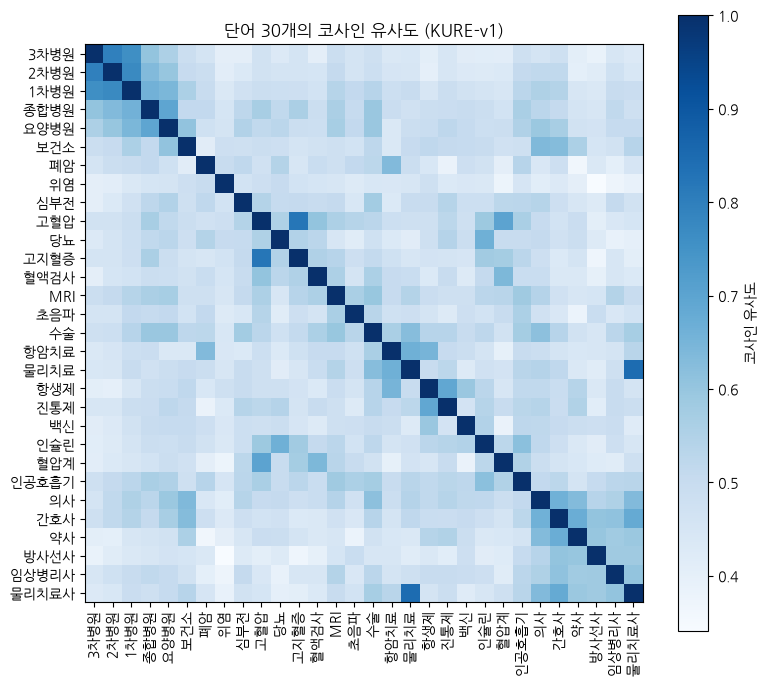

In [12]:
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(sim, cmap="Blues")
ax.set_xticks(range(len(words)), words, rotation=90)
ax.set_yticks(range(len(words)), words)
fig.colorbar(im, ax=ax, label="코사인 유사도")
ax.set_title("단어 30개의 코사인 유사도 (KURE-v1)")
plt.show()

In [13]:
same = [sim[i, j] for i in range(30) for j in range(30) if i != j and groups[i] == groups[j]]
diff = [sim[i, j] for i in range(30) for j in range(30) if groups[i] != groups[j]]
print(f"같은 범주 쌍의 평균 코사인: {np.mean(same):.3f}")
print(f"다른 범주 쌍의 평균 코사인: {np.mean(diff):.3f}")

같은 범주 쌍의 평균 코사인: 0.565
다른 범주 쌍의 평균 코사인: 0.482


In [16]:
from sklearn.neighbors import NearestNeighbors

nn = NearestNeighbors(n_neighbors=4, metric="cosine").fit(emb)
dist, idx = nn.kneighbors(emb)

rows = []
for i, w in enumerate(words):
    neighbors = [f"{words[j]}({1 - d:.2f})" for d, j in zip(dist[i][1:], idx[i][1:])]
    rows.append([w, groups[i]] + neighbors)
pd.DataFrame(rows, columns=["단어", "범주", "이웃 1", "이웃 2", "이웃 3"])

,단어,범주,이웃 1,이웃 2,이웃 3
0,3차병원,기관,2차병원(0.80),1차병원(0.76),종합병원(0.61)
1,2차병원,기관,3차병원(0.80),1차병원(0.77),종합병원(0.63)
2,1차병원,기관,2차병원(0.77),3차병원(0.76),종합병원(0.66)
3,종합병원,기관,요양병원(0.69),1차병원(0.66),2차병원(0.63)
4,요양병원,기관,종합병원(0.69),1차병원(0.64),보건소(0.61)
5,보건소,기관,의사(0.64),간호사(0.63),요양병원(0.61)
6,폐암,진단명,항암치료(0.63),당뇨(0.54),인공호흡기(0.53)
7,위염,진단명,당뇨(0.50),폐암(0.50),고혈압(0.48)
8,심부전,진단명,수술(0.58),요양병원(0.54),고혈압(0.54)
9,고혈압,진단명,고지혈증(0.82),혈압계(0.70),혈액검사(0.60)


In [18]:
nn_euc = NearestNeighbors(n_neighbors=4, metric="euclidean").fit(emb)
_, idx_euc = nn_euc.kneighbors(emb)
print("이웃 순서가 모두 같은가:", (idx == idx_euc).all())

이웃 순서가 모두 같은가: True


In [19]:
for w in ["3차병원", "간호사", "고지혈증", "항암치료"]:
    print(w, "->", model.tokenizer.tokenize(w))

3차병원 -> ['▁3', '차', '병원']
간호사 -> ['▁', '간호', '사']
고지혈증 -> ['▁고', '지', '혈', '증']
항암치료 -> ['▁항', '암', '치료']


In [22]:
new_words = ["대학병원", "치과의사", "당뇨성망막병증", "입원치료"]
new_emb = model.encode(new_words, normalize_embeddings=True)
dist, idx = nn.kneighbors(new_emb, n_neighbors=3)

for w, d, i in zip(new_words, dist, idx):
    print(w, "->", [f"{words[j]}({1 - x:.2f})" for x, j in zip(d, i)])

대학병원 -> ['종합병원(0.73)', '요양병원(0.70)', '1차병원(0.68)']
치과의사 -> ['의사(0.70)', '물리치료사(0.69)', '간호사(0.68)']
당뇨성망막병증 -> ['당뇨(0.71)', '고지혈증(0.52)', '진통제(0.49)']
입원치료 -> ['물리치료(0.67)', '수술(0.66)', '항암치료(0.66)']


In [23]:
from sklearn.decomposition import PCA
import umap

xy_pca = PCA(n_components=2, random_state=0).fit_transform(emb)
xy_umap = umap.UMAP(n_neighbors=10, min_dist=1.0, spread=5.0, metric="cosine", random_state=0).fit_transform(emb)

c:\Users\pyostry\.conda\envs\myenv312\Lib\site-packages\umap\umap_.py:1401: RuntimeWarning: divide by zero encountered in power
  return 1.0 / (1.0 + a * x ** (2 * b))
c:\Users\pyostry\.conda\envs\myenv312\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


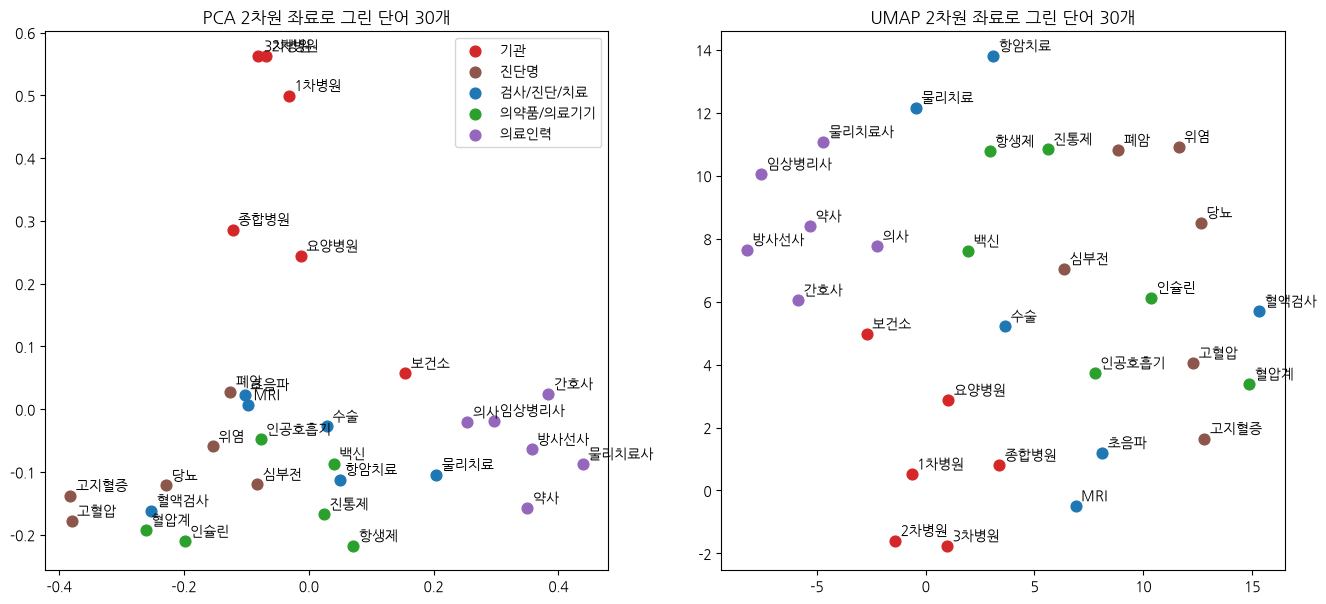

In [26]:
colors = dict(zip(words_by_group, ["tab:red", "tab:brown", "tab:blue", "tab:green", "tab:purple"]))

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, xy, title in zip(axes, [xy_pca, xy_umap], ["PCA", "UMAP"]):
    for g in words_by_group:
        m = [k for k in range(30) if groups[k] == g]
        ax.scatter(xy[m, 0], xy[m, 1], c = colors[g], label=g, s=60)
    for k, w in enumerate(words):
        ax.annotate(w, xy[k], fontsize=10, xytext=(4, 4), textcoords="offset points")
    ax.set_title(f"{title} 2차원 좌료로 그린 단어 30개")
axes[0].legend()
plt.show()


In [27]:
from sklearn.cluster import KMeans, AgglomerativeClustering, HDBSCAN
from sklearn.metrics import adjusted_rand_score

methods = {
    "K-평균": KMeans(n_clusters=5, n_init=10, random_state=0),
    "계층적 군집": AgglomerativeClustering(n_clusters=5, metric="cosine", linkage="average"),
    "HDBSCAN": HDBSCAN(min_cluster_size=3),
}
labels = {name: m.fit_predict(emb) for name, m in methods.items()}

pd.DataFrame([
    [name, len(set(lab) - {-1}), int((lab == -1).sum()), round(adjusted_rand_score(groups, lab), 3)]
    for name, lab in labels.items()
], columns=["방법", "군집 수", "이상치 수", "ARI"])

c:\Users\pyostry\.conda\envs\myenv312\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


,방법,군집 수,이상치 수,ARI
0,K-평균,5,0,0.317
1,계층적 군집,5,0,0.344
2,HDBSCAN,3,11,0.215


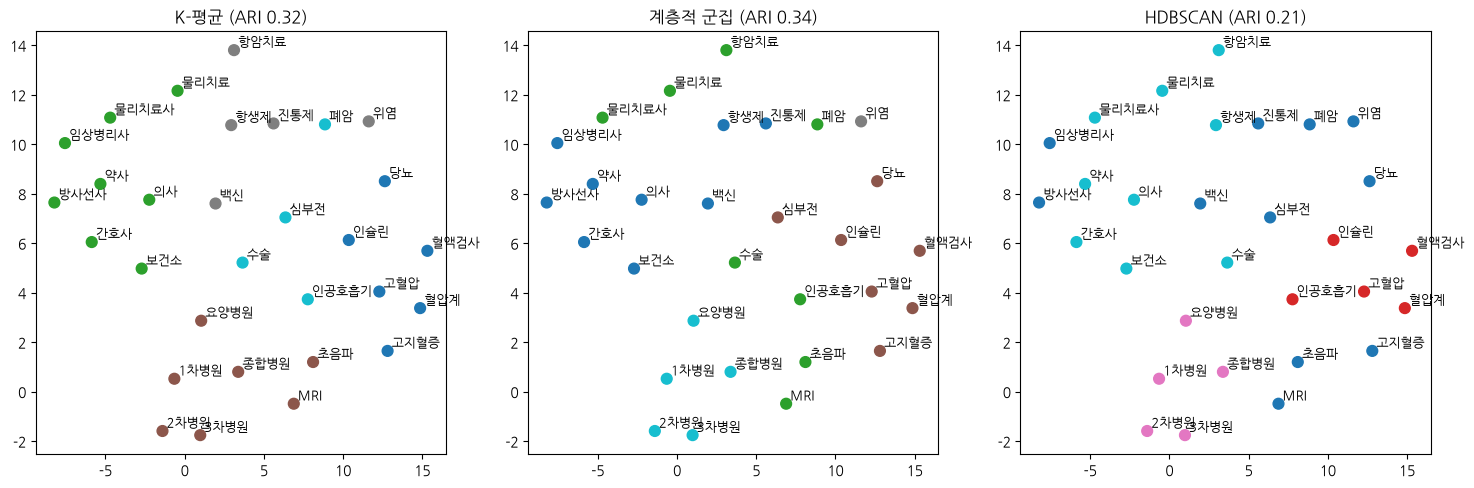

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, (name, lab) in zip(axes, labels.items()):
    ax.scatter(xy_umap[:, 0], xy_umap[:, 1], c=lab, cmap="tab10", s=60)
    for k, w in enumerate(words):
        ax.annotate(w, xy_umap[k], fontsize=9, xytext=(3, 3), textcoords="offset points")
    ax.set_title(f"{name} (ARI {adjusted_rand_score(groups, lab):.2f})")
plt.show()

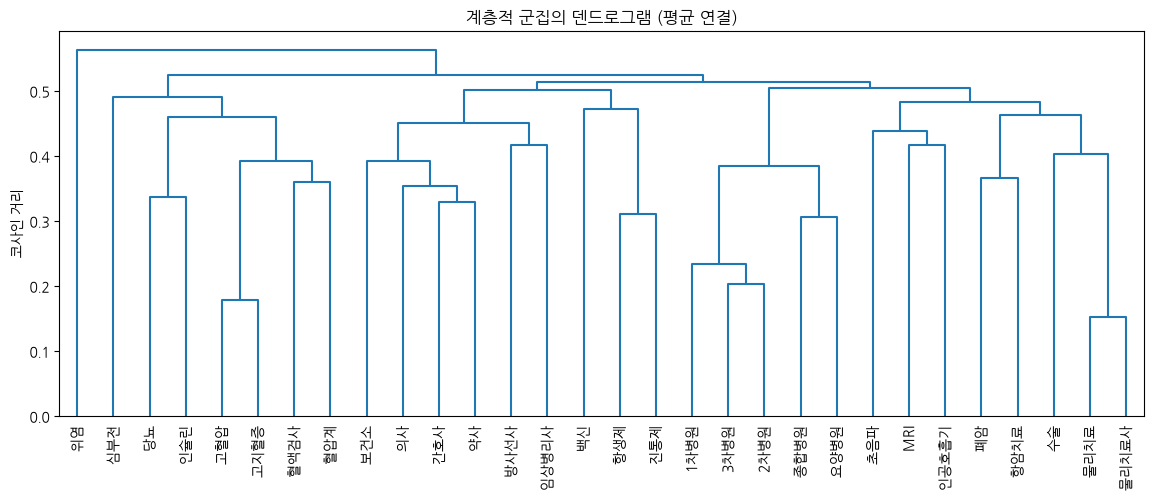

In [29]:
from scipy.cluster.hierarchy import linkage, dendrogram

Z = linkage(emb, method="average", metric="cosine")
plt.figure(figsize=(14, 5))
dendrogram(Z, labels=words, leaf_rotation=90, color_threshold=0, above_threshold_color="tab:blue")
plt.ylabel("코사인 거리")
plt.title("계층적 군집의 덴드로그램 (평균 연결)")
plt.show()

In [30]:
candidates = {
    "nlpai-lab/KURE-v1": "",
    "intfloat/multilingual-e5-small": "query: ",
    "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2": "",
}

rows = []
for name, prefix in candidates.items():
    m = SentenceTransformer(name, device=device)
    e = m.encode([prefix + w for w in words], normalize_embeddings=True)
    s = e @ e.T
    same = np.mean([s[i, j] for i in range(30) for j in range(30) if i != j and groups[i] == groups[j]])
    diff = np.mean([s[i, j] for i in range(30) for j in range(30) if groups[i] != groups[j]])
    ari = adjusted_rand_score(groups, KMeans(n_clusters=5, n_init=10, random_state=0).fit_predict(e))
    rows.append([name.split("/")[-1], e.shape[1], round(same, 3), round(diff, 3), round(ari, 3)])

pd.DataFrame(rows, columns=["모델", "차원", "같은 범주 평균 코사인", "다른 범주 평균 코사인", "K-평균 ARI"])

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2677.30it/s]


,모델,차원,같은 범주 평균 코사인,다른 범주 평균 코사인,K-평균 ARI
0,KURE-v1,1024,0.565,0.482,0.317
1,multilingual-e5-small,384,0.851,0.830,0.246
2,paraphrase-multilingual-MiniLM-L12-v2,384,0.581,0.465,0.238
